In [31]:
import matplotlib.pyplot as plt
import numpy as np
import time

In [32]:
#### CONSTANTES FÍSICAS 
## Vamos a trabajar en años
# T12 = 5730.0
# Lambda = np.log(2)/T12

T12 = np.log(2)
Lambda = np.log(2) / T12

n0 = 10**3  # número de núcleos a tiempo 0

t = 5       # tiempo total que vamos a simular
dt = 0.05    # intervalo de tiempo
u = int(t/dt)  # número de intervalos
tiempos = np.arange(u + 1) * dt

N_teorico = n0 * np.exp(-Lambda * tiempos)


# Posición del tiempo de vida media
pos_t12 = int(round(T12 / dt))

num_simulaciones = 50



In [33]:
inicio = time.perf_counter()
np.random.seed(4321)

M = np.zeros((num_simulaciones, u + 1))

q_step = np.exp(-Lambda * dt)

for i in range(num_simulaciones):
    N = n0
    M[i, 0] = N

    for j in range(1, u + 1):
        N = np.random.binomial(N, q_step)
        M[i, j] = N

fin = time.perf_counter()

media_exp = np.mean(M, axis=0)
desviacion_exp = np.std(M, axis=0, ddof=1)


np.savetxt("Matriz_binomial_500sim_1000nucleos.txt", M)

print(f"Tiempo de ejecución: {fin - inicio} segundos")

Tiempo de ejecución: 0.005967642000541673 segundos


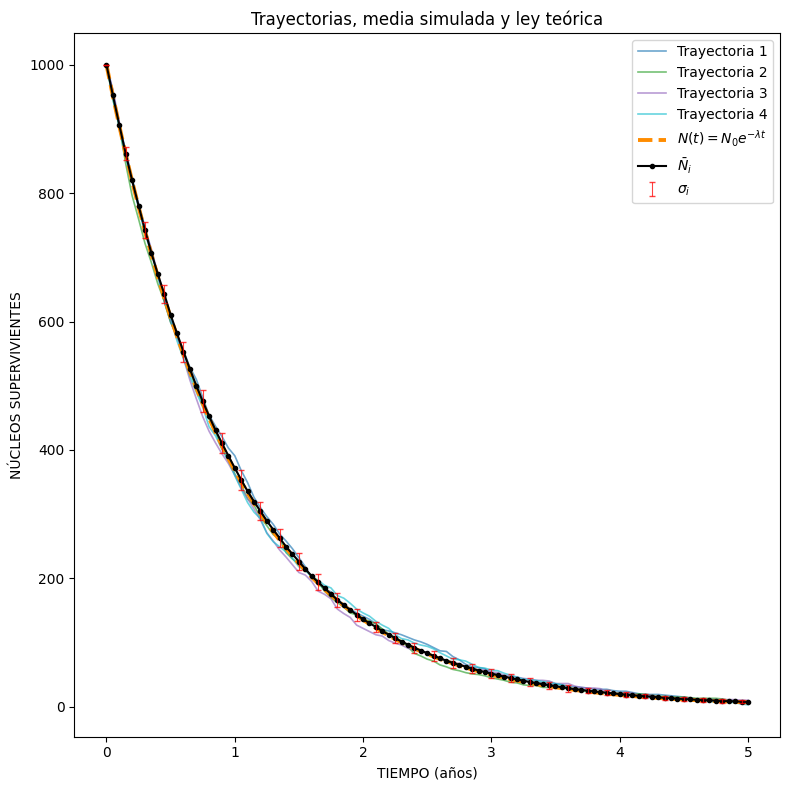

In [34]:
##########################################
############ PRIMERA GRÁFICA ############
#########################################

trayectorias = [0, 1, 2, 3]

plt.figure(figsize=(8, 8))

# Trayectorias individuales
colores_trayectorias = ["tab:blue", "tab:green", "tab:purple", "tab:cyan"]

for i, color in zip(trayectorias, colores_trayectorias):
    plt.plot(
        tiempos,
        M[i, :],
        color=color,
        linewidth=1.2,
        alpha=0.65,
        label=f"Trayectoria {i+1}"
    )

# Curva teórica
plt.plot(
    tiempos,
    N_teorico,
    color="darkorange",
    linestyle="--",
    linewidth=2.8,
    label=r"$N(t)=N_0e^{-\lambda t}$"
)

# Media simulada como línea negra
plt.plot(
    tiempos,
    media_exp,
    color="black",
    linewidth=1.5,
    marker="o",
    markersize=3,
    label=r"$\bar{N}_i$"
)

# Barras de error solo cada varios puntos
salto = 3

plt.errorbar(
    tiempos[::salto],
    media_exp[::salto],
    yerr=desviacion_exp[::salto],
    fmt="none",
    ecolor="red",
    elinewidth=0.8,
    capsize=2,
    alpha=0.75,
    label=r"$\sigma_i$"
)

plt.xlabel("TIEMPO (años)")
plt.ylabel("NÚCLEOS SUPERVIVIENTES")
plt.title("Trayectorias, media simulada y ley teórica")
plt.legend()
plt.tight_layout()
plt.savefig("figura1_trayectorias.png", dpi=300)
plt.show()

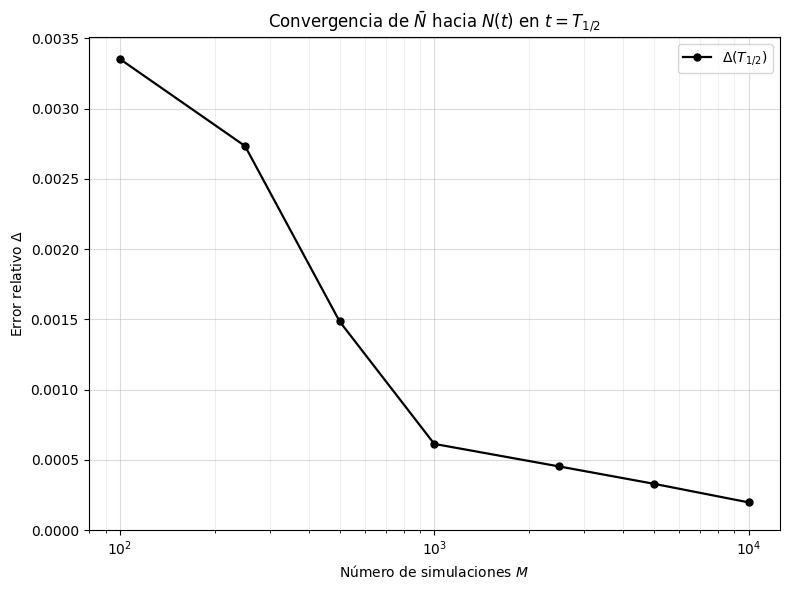

In [35]:
##########################################
############ SEGUNDA GRÁFICA ############
##########################################

valores_M = [100, 250, 500, 1000, 2500, 5000, 10000]
errores_delta = []
np.random.seed(4321)

for M_sim in valores_M:

    matriz = np.zeros((M_sim, u + 1))

    for i in range(M_sim):
        N = n0
        matriz[i, 0] = N

        for j in range(1, u + 1):
            N = np.random.binomial(N, q_step)
            matriz[i, j] = N

    media_t12 = np.mean(matriz[:, pos_t12])

    teorico_t12 = n0 * np.exp(-Lambda * tiempos[pos_t12])

    Delta = abs(media_t12 - teorico_t12) / teorico_t12

    errores_delta.append(Delta)


plt.figure(figsize=(8, 6))

plt.plot(
    valores_M,
    errores_delta,
    "o-",
    color="black",
    linewidth=1.6,
    markersize=5,
    label=r"$\Delta(T_{1/2})$"
)

plt.xscale("log")

plt.xlabel(r"Número de simulaciones $M$")
plt.ylabel(r"Error relativo $\Delta$")
plt.title(r"Convergencia de $\bar{N}$ hacia $N(t)$ en $t=T_{1/2}$")

plt.grid(True, which="major", alpha=0.45)
plt.grid(True, which="minor", alpha=0.20)

plt.ylim(bottom=0)

plt.legend()
plt.tight_layout()
plt.savefig("figura2_convergencia_t12.png", dpi=300)
plt.show()

M =    100 | error máximo = 0.07174
M =    250 | error máximo = 0.01252
M =    500 | error máximo = 0.00937
M =   1000 | error máximo = 0.00816
M =   2500 | error máximo = 0.00813
M =   5000 | error máximo = 0.00495
M =  10000 | error máximo = 0.00736


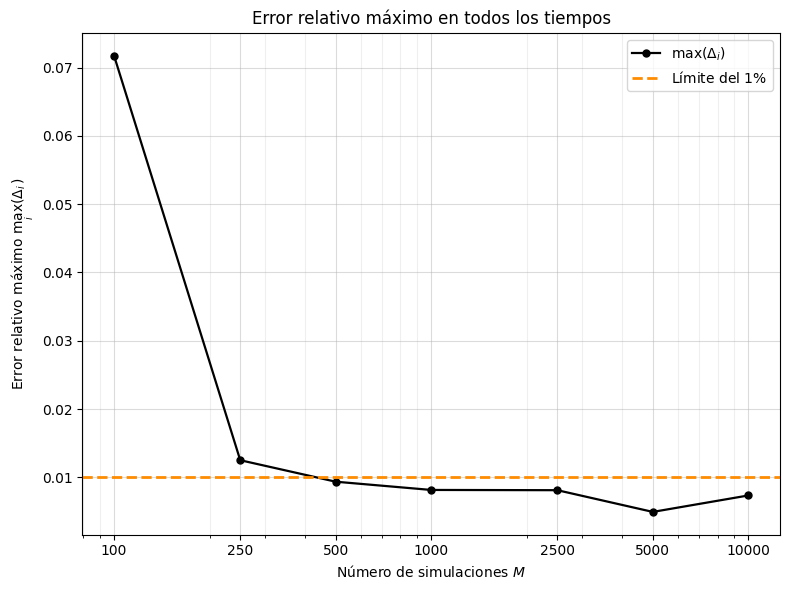

In [36]:
valores_M = [100, 250, 500, 1000, 2500, 5000, 10000]
errores_maximos = []

np.random.seed(4321)

for M_sim in valores_M:

    matriz = np.zeros((M_sim, u + 1))

    for i in range(M_sim):
        N = n0
        matriz[i, 0] = N

        for j in range(1, u + 1):
            N = np.random.binomial(N, q_step)
            matriz[i, j] = N

    media = np.mean(matriz, axis=0)

    Delta = np.abs(media - N_teorico) / N_teorico

    error_maximo = np.max(Delta)
    errores_maximos.append(error_maximo)

    print(f"M = {M_sim:6d} | error máximo = {error_maximo:.5f}")


plt.figure(figsize=(8, 6))

plt.plot(
    valores_M,
    errores_maximos,
    "o-",
    color="black",
    linewidth=1.6,
    markersize=5,
    label=r"$\max(\Delta_i)$"
)

plt.axhline(
    0.01,
    color="darkorange",
    linestyle="--",
    linewidth=2,
    label=r"Límite del $1\%$"
)

plt.xscale("log")
plt.xticks(valores_M, valores_M)

plt.xlabel(r"Número de simulaciones $M$")
plt.ylabel(r"Error relativo máximo $\max_i(\Delta_i)$")
plt.title("Error relativo máximo en todos los tiempos")

plt.grid(True, which="major", alpha=0.45)
plt.grid(True, which="minor", alpha=0.20)

plt.legend()
plt.tight_layout()
plt.savefig("error_maximo_vs_M.png", dpi=300)
plt.show()